Apply Coverage and Identity Diferent Threshold <br>
Identity:30%    Coverage: 80%<br>
Identity:40%    Coverage: 80%<br>
Identity:50%    Coverage: 80%<br>

In [ ]:
import pandas as pd

thresholds = {
    30: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/30%_80%/cluster_result_30.tsv',
    40: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/40%_80%/cluster_result_40.tsv',
    50: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/50%_80%/cluster_result_50.tsv'
}

for thresh, path in thresholds.items():
    df = pd.read_csv(path, sep='\t', header=None, names=['representative', 'member'])
    n_clusters = df['representative'].nunique()
    n_sequences = len(df)
    avg_cluster_size = n_sequences / n_clusters
    print(f"Threshold {thresh}%: {n_clusters} clusters, {n_sequences} sequences, avg cluster size {avg_cluster_size:.2f}")

Threshold 30%: 3325 clusters, 3655 sequences, avg cluster size 1.10
Threshold 40%: 3429 clusters, 3655 sequences, avg cluster size 1.07
Threshold 50%: 3521 clusters, 3655 sequences, avg cluster size 1.04


                     30         40         50
class                                        
Non-secreted   2.485207   1.124260   0.591716
Sec            9.451220   7.621951   4.268293
T1SS          20.945946  16.216216  10.810811
T2SS          11.538462  10.256410   2.564103
T3SS          15.695067  12.107623   7.399103
T4SS           3.423423   2.522523   1.261261
T5SS          28.205128  25.641026  17.948718
T6SS          30.545455  16.000000   8.727273
Tat           30.208333  26.041667  18.750000


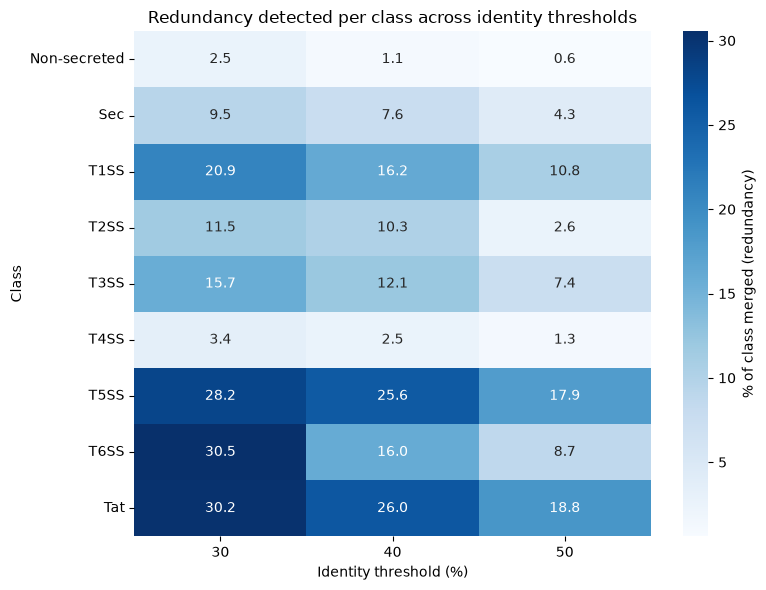

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def get_class(seq_id):
    return seq_id.rsplit('-', 1)[0]

thresholds = {
    30: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/30%_80%/cluster_result_30.tsv',
    40: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/40%_80%/cluster_result_40.tsv',
    50: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/50%_80%/cluster_result_50.tsv'
}


class_redundancy = {}

for thresh, path in thresholds.items():
    df = pd.read_csv(path, sep='\t', header=None, names=['representative', 'member'])
    df['class'] = df['member'].apply(get_class)
    
    # total sequences per class
    total_per_class = df.groupby('class').size()
    # unique clusters per class (representative count, per class)
    unique_clusters_per_class = df.groupby('class')['representative'].nunique()
    
    merged = total_per_class - unique_clusters_per_class
    pct_merged = (merged / total_per_class) * 100
    class_redundancy[thresh] = pct_merged

heatmap_df = pd.DataFrame(class_redundancy)
print(heatmap_df)

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_df, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% of class merged (redundancy)'})
plt.title('Redundancy detected per class across identity thresholds')
plt.xlabel('Identity threshold (%)')
plt.ylabel('Class')
plt.tight_layout()
plt.savefig('threshold_comparison_heatmap.png', dpi=150)
plt.show()

Create .csv file Based on Cluster_id of each class <br>




In [28]:
import pandas as pd

df = pd.read_csv('C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/30%_80%/cluster_result_30.tsv', sep='\t', header=None, names=['representative', 'member'])
df['label'] = df['member'].apply(lambda x: x.rsplit('-', 1)[0])

# Give each cluster a readable, per-class sequential ID (Sec_1, Sec_2...) instead of raw MMseqs2 representative
cluster_id_map = {}
class_counters = {}

for rep in df['representative'].unique():
    cls = df[df['representative'] == rep]['label'].iloc[0]
    class_counters.setdefault(cls, 0)
    class_counters[cls] += 1
    cluster_id_map[rep] = f"{cls}_{class_counters[cls]}"

df['cluster_id'] = df['representative'].map(cluster_id_map)

final_df = df[['label', 'cluster_id', 'member']].rename(columns={'member': 'Protein_id'})
final_df = final_df.sort_values(['label', 'cluster_id']).reset_index(drop=True)

final_df.to_csv('seq_cluster_class_final.csv', index=False,sep=";")
print(final_df.head(20))
print("\nTotal rows:", len(final_df))

           label         cluster_id         Protein_id
0   Non-secreted     Non-secreted_1    Non-secreted-26
1   Non-secreted    Non-secreted_10   Non-secreted-314
2   Non-secreted   Non-secreted_100  Non-secreted-1540
3   Non-secreted  Non-secreted_1000   Non-secreted-207
4   Non-secreted  Non-secreted_1001   Non-secreted-239
5   Non-secreted  Non-secreted_1002   Non-secreted-271
6   Non-secreted  Non-secreted_1003   Non-secreted-303
7   Non-secreted  Non-secreted_1004   Non-secreted-335
8   Non-secreted  Non-secreted_1005   Non-secreted-367
9   Non-secreted  Non-secreted_1006   Non-secreted-399
10  Non-secreted  Non-secreted_1007   Non-secreted-431
11  Non-secreted  Non-secreted_1007  Non-secreted-1351
12  Non-secreted  Non-secreted_1008   Non-secreted-463
13  Non-secreted  Non-secreted_1009   Non-secreted-495
14  Non-secreted   Non-secreted_101  Non-secreted-1572
15  Non-secreted  Non-secreted_1010   Non-secreted-527
16  Non-secreted  Non-secreted_1011   Non-secreted-559
17  Non-se

Add new column Every cluster_id how much protein sequence.<br>
Cumulate each cluster protein sequence <br>
Compute how many percentage of each class Protein sequence count. <br>


In [30]:
import pandas as pd

df = pd.read_csv('seq_cluster_class_final.csv',sep=";")  # your existing per-protein file

# cluster-level size
cluster_sizes = df.groupby(['label', 'cluster_id']).size().reset_index(name='cluster_size')

# sort within each class by cluster_size descending — matches greedy bin-packing order
cluster_sizes = cluster_sizes.sort_values(['label', 'cluster_size'], ascending=[True, False]).reset_index(drop=True)

# cumulative protein count, RESETTING per class
cluster_sizes['cumulative_protein'] = cluster_sizes.groupby('label')['cluster_size'].cumsum()

# total proteins per class (constant across that class's rows)
class_totals = cluster_sizes.groupby('label')['cluster_size'].sum()
cluster_sizes['class_total_protein'] = cluster_sizes['label'].map(class_totals)

# percentage coverage so far, within that class
cluster_sizes['percentage_seq_cover'] = (cluster_sizes['cumulative_protein'] / cluster_sizes['class_total_protein'] * 100).round(2)

cluster_sizes.to_csv('cluster_summary.csv', index=False, sep=';')
print(cluster_sizes.head(20))
print("\nTotal rows (clusters):", len(cluster_sizes))

           label         cluster_id  cluster_size  cumulative_protein  \
0   Non-secreted   Non-secreted_627             3                   3   
1   Non-secreted  Non-secreted_1007             2                   5   
2   Non-secreted  Non-secreted_1053             2                   7   
3   Non-secreted  Non-secreted_1056             2                   9   
4   Non-secreted  Non-secreted_1078             2                  11   
5   Non-secreted  Non-secreted_1258             2                  13   
6   Non-secreted  Non-secreted_1265             2                  15   
7   Non-secreted  Non-secreted_1312             2                  17   
8   Non-secreted  Non-secreted_1318             2                  19   
9   Non-secreted  Non-secreted_1333             2                  21   
10  Non-secreted  Non-secreted_1369             2                  23   
11  Non-secreted  Non-secreted_1414             2                  25   
12  Non-secreted  Non-secreted_1449             2  

Add new column Train/Test based on percentage of protein sequence cover<br>
(Protein_seq <=80) ==> Train label assign else Test

In [34]:
import pandas as pd

df = pd.read_csv('cluster_summary.csv', sep=';')

df['Train/Test_Split'] = df['percentage_seq_cover'].apply(lambda x: 'train' if x <= 80 else 'test')

df.to_csv('cluster_summary_train_test.csv', index=False, sep=';')
print(df.head(20))

           label         cluster_id  cluster_size  cumulative_protein  \
0   Non-secreted   Non-secreted_627             3                   3   
1   Non-secreted  Non-secreted_1007             2                   5   
2   Non-secreted  Non-secreted_1053             2                   7   
3   Non-secreted  Non-secreted_1056             2                   9   
4   Non-secreted  Non-secreted_1078             2                  11   
5   Non-secreted  Non-secreted_1258             2                  13   
6   Non-secreted  Non-secreted_1265             2                  15   
7   Non-secreted  Non-secreted_1312             2                  17   
8   Non-secreted  Non-secreted_1318             2                  19   
9   Non-secreted  Non-secreted_1333             2                  21   
10  Non-secreted  Non-secreted_1369             2                  23   
11  Non-secreted  Non-secreted_1414             2                  25   
12  Non-secreted  Non-secreted_1449             2  

Compute Train.csv and Test.csv file based on Final Train/Test  column<br>
Train.csv ==> Label, Protein_id, cluster_id , Protein_sequence <br>
Test.csv ==> Label, Protein_id, cluster_id , Protein_sequence 

In [38]:
import pandas as pd

# your final split decision, cluster-level
cluster_df = pd.read_csv('cluster_summary_train_test.csv', sep=';')

# protein-level file (has Protein_id + cluster_id + label)
protein_df = pd.read_csv('seq_cluster_class_final.csv', sep=';')

# map cluster's split decision onto every protein in that cluster
split_map = cluster_df.set_index('cluster_id')['Train/Test_Split'].to_dict()
protein_df['final_split'] = protein_df['cluster_id'].map(split_map)

# real check — confirm nothing missed
missing = protein_df['final_split'].isna().sum()
print("Proteins with no split assigned (should be 0):", missing)

# load actual sequences from your clean fasta
def load_fasta(path):
    seqs = {}
    current_id, current_seq = None, []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line.startswith('>'):
                if current_id:
                    seqs[current_id] = ''.join(current_seq)
                current_id = line[1:]
                current_seq = []
            else:
                current_seq.append(line)
        if current_id:
            seqs[current_id] = ''.join(current_seq)
    return seqs

seqs = load_fasta('combine_final.fasta')
protein_df['Sequence'] = protein_df['Protein_id'].map(seqs)

# reorder columns to match your requested structure
final_df = protein_df[['Protein_id', 'cluster_id', 'label', 'final_split', 'Sequence']]
final_df = final_df.rename(columns={'cluster_id': 'Cluster_id'})

# split and save
train_df = final_df[final_df['final_split'] == 'train'].reset_index(drop=True)
test_df = final_df[final_df['final_split'] == 'test'].reset_index(drop=True)

train_df.to_csv('train.csv', index=False, sep=';')
test_df.to_csv('test.csv', index=False, sep=';')

print("Train rows:", len(train_df))
print("Test rows:", len(test_df))
print(train_df.head(10))

Proteins with no split assigned (should be 0): 0
Train rows: 2917
Test rows: 734
          Protein_id         Cluster_id         label final_split  \
0    Non-secreted-26     Non-secreted_1  Non-secreted       train   
1   Non-secreted-314    Non-secreted_10  Non-secreted       train   
2  Non-secreted-1540   Non-secreted_100  Non-secreted       train   
3   Non-secreted-207  Non-secreted_1000  Non-secreted       train   
4   Non-secreted-239  Non-secreted_1001  Non-secreted       train   
5   Non-secreted-271  Non-secreted_1002  Non-secreted       train   
6   Non-secreted-303  Non-secreted_1003  Non-secreted       train   
7   Non-secreted-335  Non-secreted_1004  Non-secreted       train   
8   Non-secreted-367  Non-secreted_1005  Non-secreted       train   
9   Non-secreted-399  Non-secreted_1006  Non-secreted       train   

                                            Sequence  
0  MSSDLRKPLLGRQKKSAGINRRFSVIMLLSVLAVLSIGGLSIYTAL...  
1  MYSVCFRFTKLLITTICCYCKESIVDALAAYSKVNQQTQEALVKTH

In [39]:
import pandas as pd

def csv_to_fasta(csv_path, fasta_path):
    df = pd.read_csv(csv_path, sep=';')
    with open(fasta_path, 'w') as f:
        for _, row in df.iterrows():
            f.write(f">{row['Protein_id']}\n{row['Sequence']}\n")
    print(f"Saved: {fasta_path}, {len(df)} sequences")

csv_to_fasta('train.csv', 'train.fasta')
csv_to_fasta('test.csv', 'test.fasta')

Saved: train.fasta, 2917 sequences
Saved: test.fasta, 734 sequences


In [43]:
# Part 1 — total in source combine file
total_combine = sum(1 for line in open('combine_final.fasta') if line.startswith('>'))
print("Total sequences in combine_final.fasta:", total_combine)

# Part 2 — per-class counts in new train/test
from collections import defaultdict

def class_counts(path):
    counts = defaultdict(int)
    with open(path) as f:
        for line in f:
            if line.startswith('>'):
                seq_id = line[1:].strip()
                cls = seq_id.rsplit('-', 1)[0]
                counts[cls] += 1
    return counts

train_counts = class_counts('train.fasta')
test_counts = class_counts('test.fasta')

print("\n--- TRAIN ---")
for cls in sorted(train_counts):
    print(f"{cls}: {train_counts[cls]}")
print("Total train:", sum(train_counts.values()))

print("\n--- TEST ---")
for cls in sorted(test_counts):
    print(f"{cls}: {test_counts[cls]}")
print("Total test:", sum(test_counts.values()))

print("\n--- COMBINED (train+test), per class ---")
all_classes = set(train_counts) | set(test_counts)
for cls in sorted(all_classes):
    t = train_counts.get(cls, 0)
    te = test_counts.get(cls, 0)
    total = t + te
    pct = round(t/total*100, 1) if total else 0
    print(f"{cls}: train={t}, test={te}, total={total}, train%={pct}")

Total sequences in combine_final.fasta: 3651

--- TRAIN ---
Non-secreted: 1350
Sec: 262
T1SS: 118
T2SS: 62
T3SS: 356
T4SS: 442
T5SS: 31
T6SS: 220
Tat: 76
Total train: 2917

--- TEST ---
Non-secreted: 338
Sec: 66
T1SS: 30
T2SS: 16
T3SS: 90
T4SS: 111
T5SS: 8
T6SS: 55
Tat: 20
Total test: 734

--- COMBINED (train+test), per class ---
Non-secreted: train=1350, test=338, total=1688, train%=80.0
Sec: train=262, test=66, total=328, train%=79.9
T1SS: train=118, test=30, total=148, train%=79.7
T2SS: train=62, test=16, total=78, train%=79.5
T3SS: train=356, test=90, total=446, train%=79.8
T4SS: train=442, test=111, total=553, train%=79.9
T5SS: train=31, test=8, total=39, train%=79.5
T6SS: train=220, test=55, total=275, train%=80.0
Tat: train=76, test=20, total=96, train%=79.2
